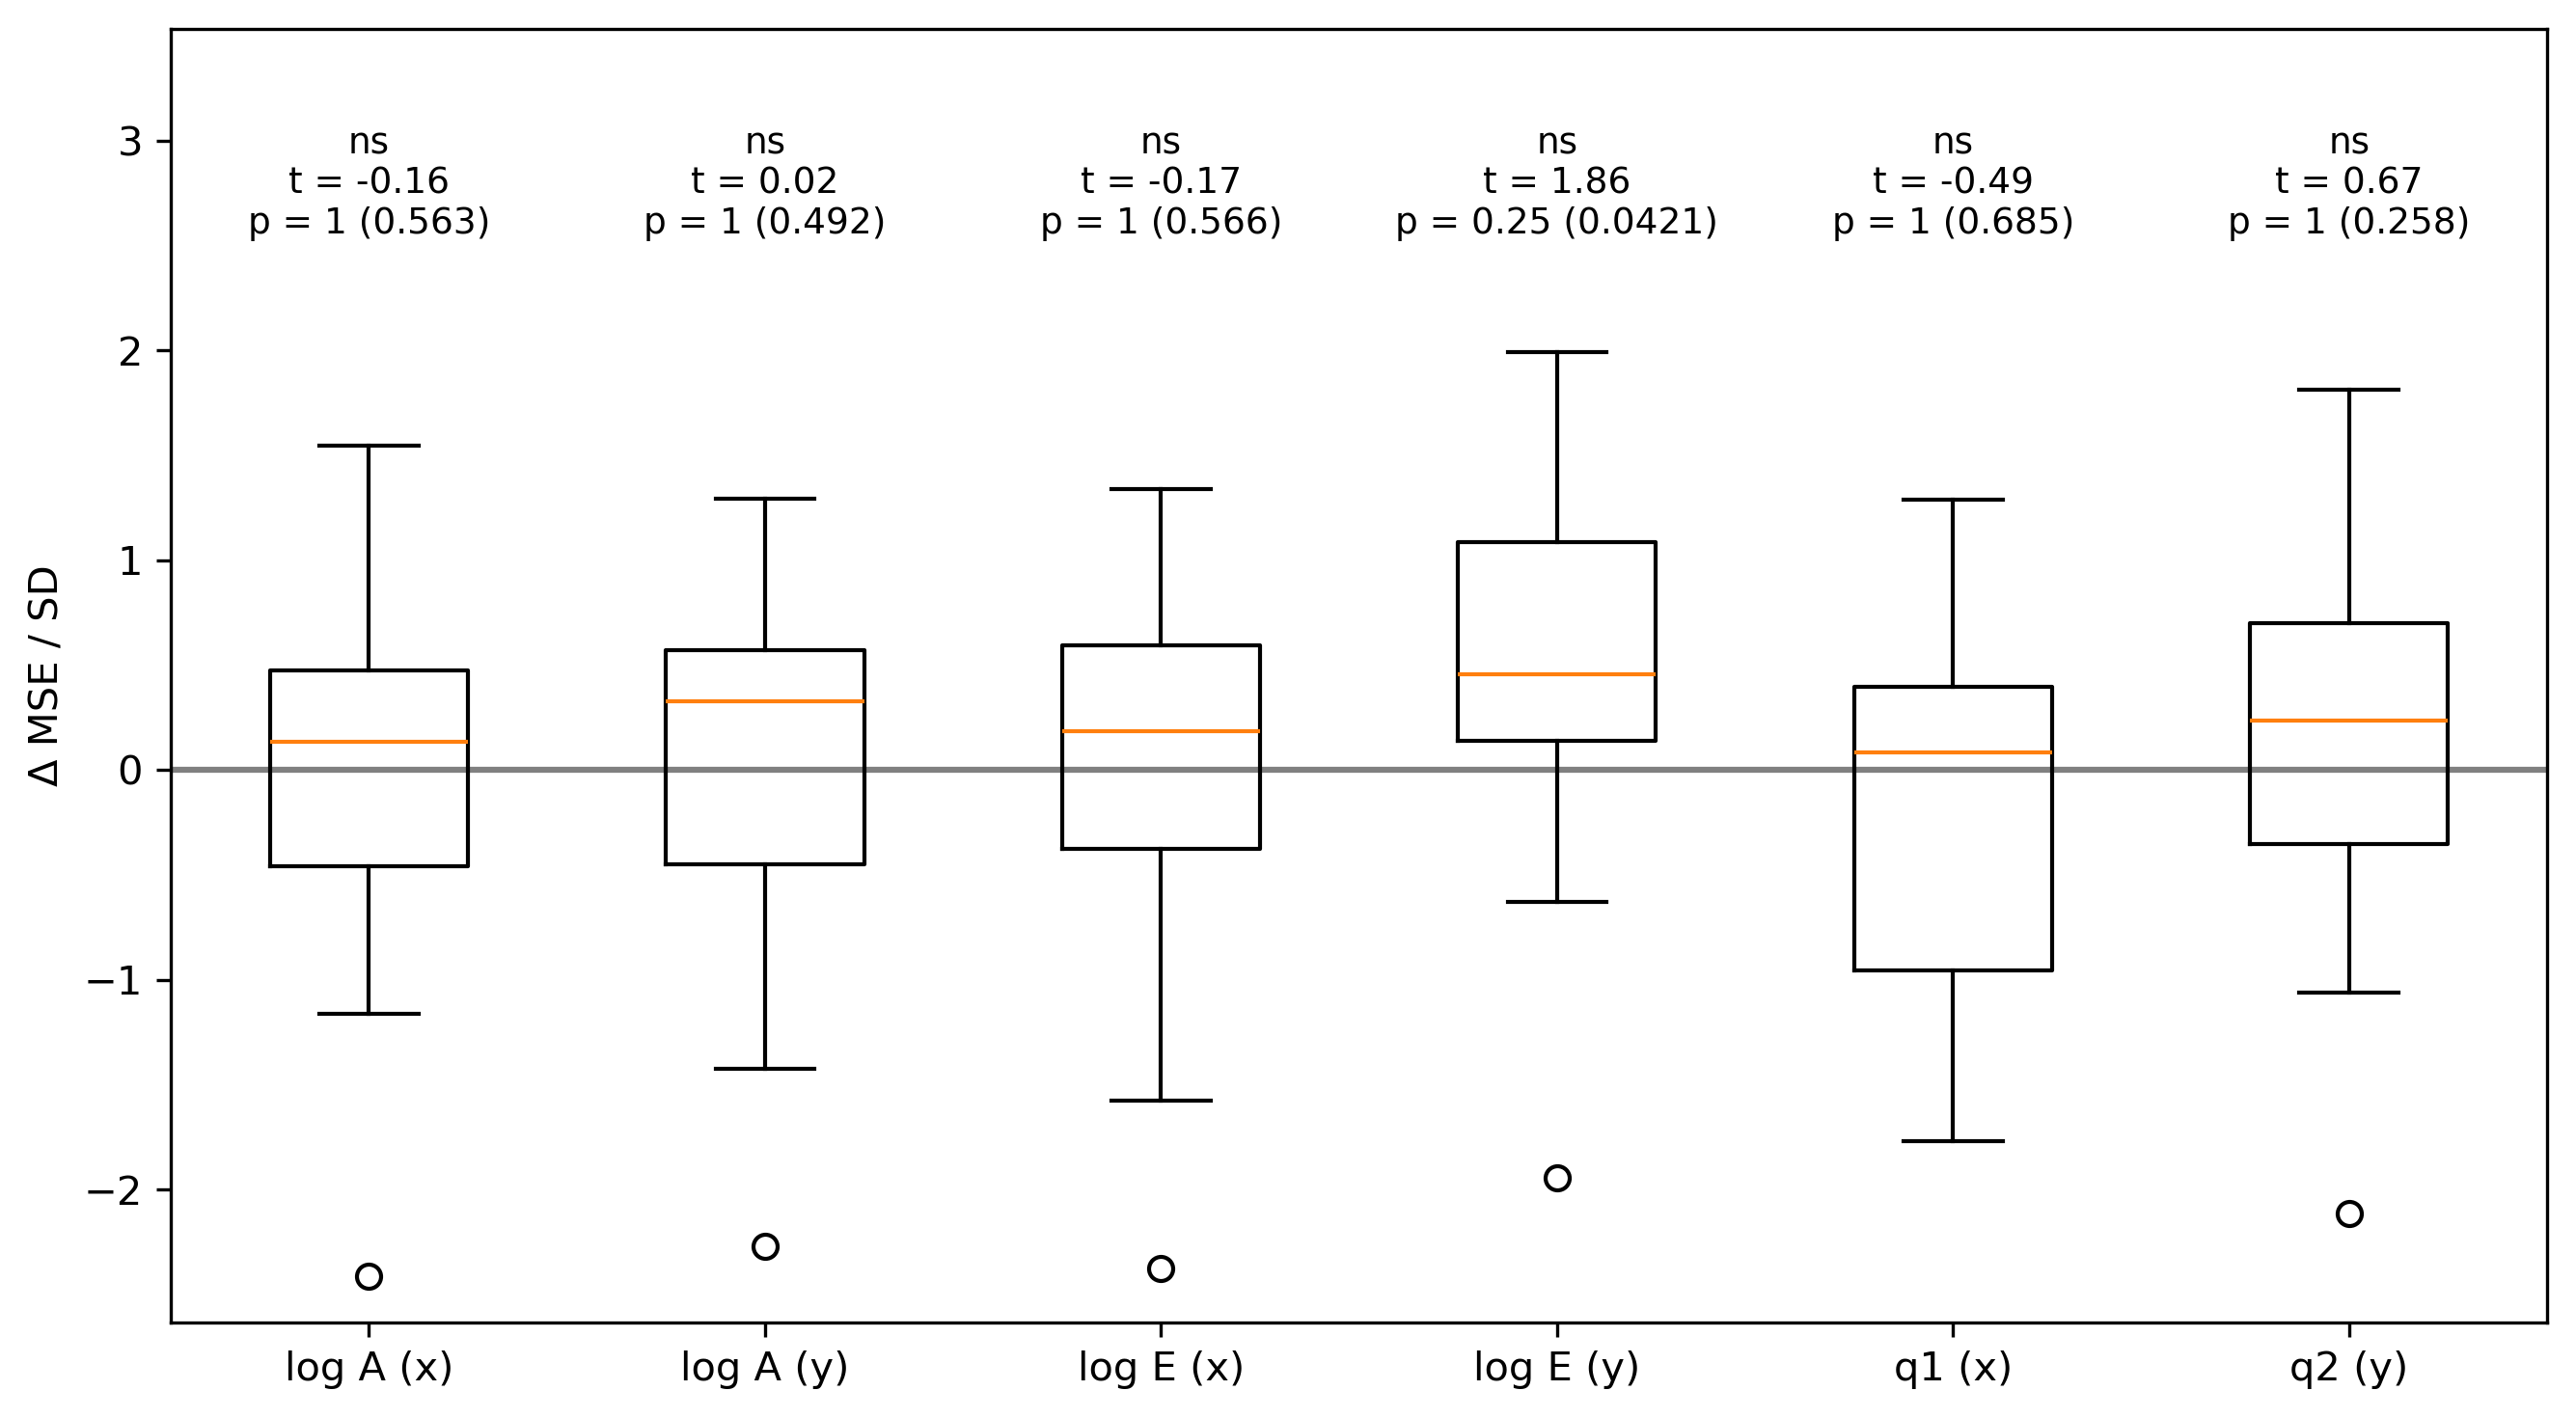

In [1]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_1samp

datasets = {
    "log A (x)": "../output/dataset_Ax.pkl",
    "log A (y)": "../output/dataset_Ay.pkl",
    "log E (x)": "../output/dataset_Ex.pkl",
    "log E (y)": "../output/dataset_Ey.pkl",
    "q1 (x)": "../output/dataset_qx.pkl",
    "q2 (y)": "../output/dataset_qy.pkl",
}

# Bonferroni: number of tests in this figure (6 channels, pooled GAM only)
n_tests = len(datasets)

data = {}

for name, filename in datasets.items():
    with open(filename, "rb") as f:
        arr = np.asarray(pickle.load(f), dtype=float)

    sd = np.std(arr, ddof=1)

    if sd == 0:
        raise ValueError(f"Standard deviation is zero for {name}")

    data[name] = arr / sd

labels = list(data.keys())
values = list(data.values())

fig, ax = plt.subplots(figsize=(9, 5), dpi=300)

ax.axhline(
    0,
    color="grey",
    linestyle="-",
)

ax.boxplot(
    values,
    tick_labels=labels,
)

y_min = min(np.min(v) for v in values)
y_max = max(np.max(v) for v in values)
y_range = y_max - y_min

annotation_y = y_max + 0.12 * y_range

for i, values_i in enumerate(values, start=1):
    t_stat, p_value = ttest_1samp(
        values_i,
        popmean=0.0,
        alternative="greater",
    )

    p_corrected = min(1.0, p_value * n_tests)

    if p_corrected < 0.001:
        sig = "***"
    elif p_corrected < 0.01:
        sig = "**"
    elif p_corrected < 0.05:
        sig = "*"
    else:
        sig = "ns"

    ax.text(
        i,
        annotation_y,
        f"{sig}\nt = {t_stat:.2f}\np = {p_corrected:.2g} ({p_value:.3g})",
        ha="center",
        va="bottom",
        fontsize=9,
    )

ax.set_ylim(
    y_min - 0.05 * y_range,
    y_max + 0.35 * y_range,
)

ax.set_ylabel("Δ MSE / SD")

fig.tight_layout()
plt.show()

# Combined boxplot: pooled vs. cell-specific bias

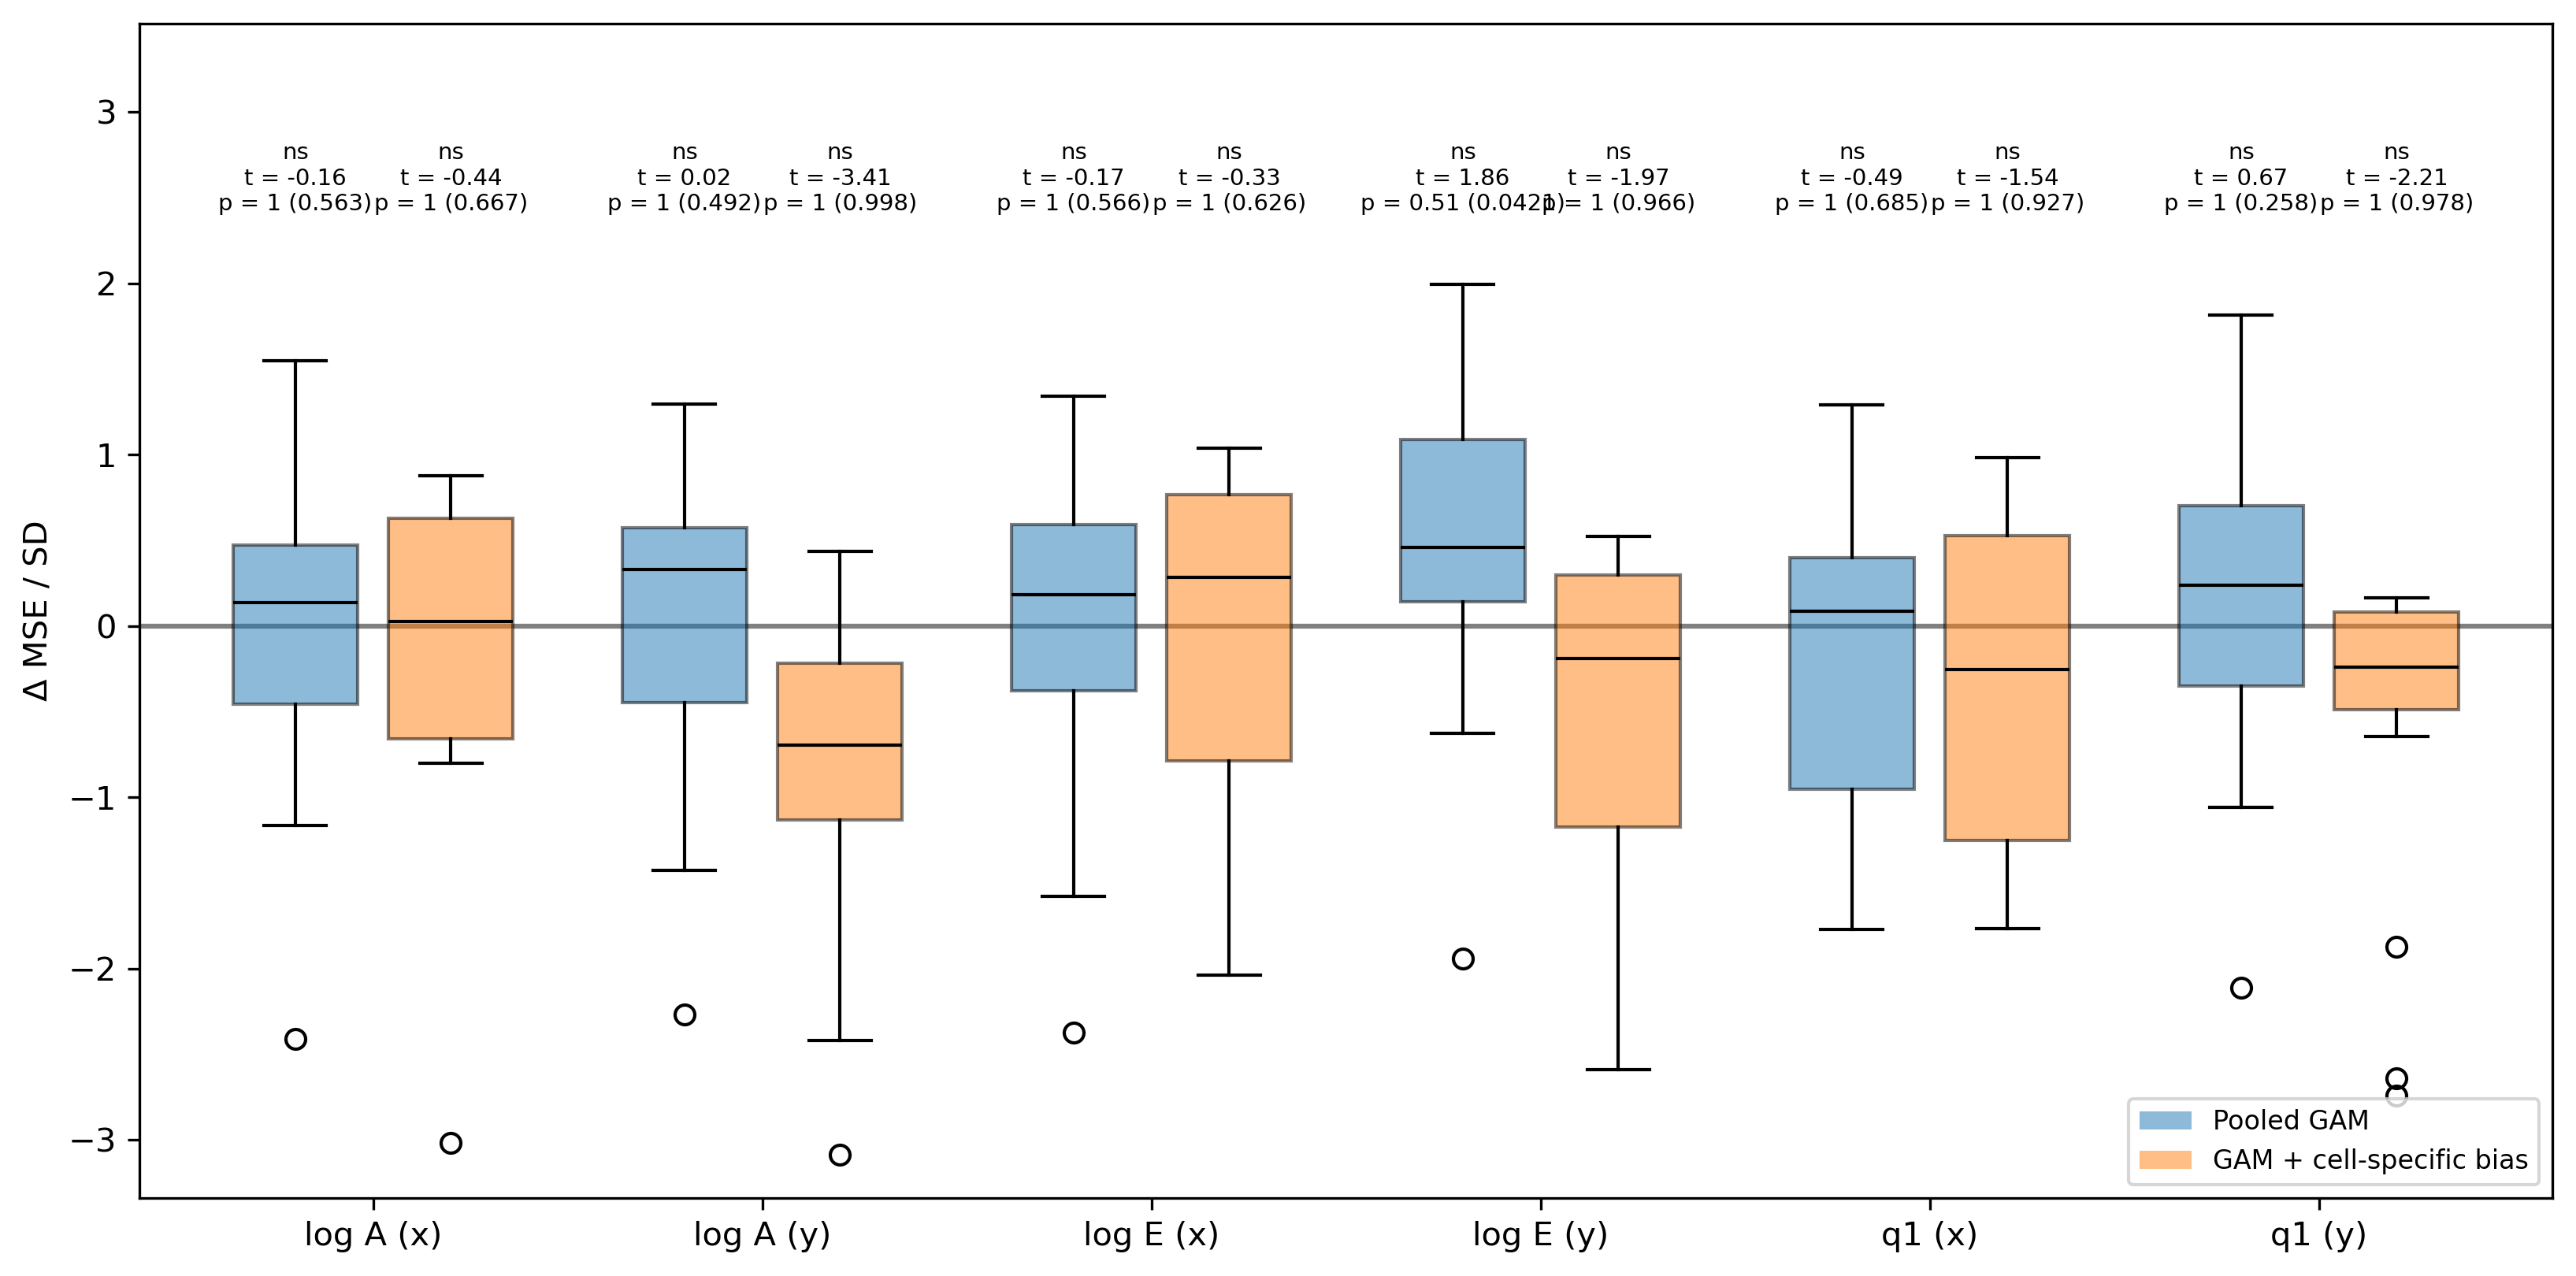

p values: one-sided t-test across outer folds, Bonferroni-corrected for 12 tests (p x 12, capped at 1). Uncorrected p in parentheses. Stars use the corrected p.
Pooled GAM: Fisher combined p = 0.333 (6 channels)
GAM + cell-specific bias: Fisher combined p = 0.999 (6 channels)
Fisher assumes independent tests but channels are positively correlated, so the combined p is anti-conservative.


In [2]:
import pickle
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import combine_pvalues, ttest_1samp

channels = {
    "log A (x)": "Ax",
    "log A (y)": "Ay",
    "log E (x)": "Ex",
    "log E (y)": "Ey",
    "q1 (x)": "qx",
    "q1 (y)": "qy",
}

models = {
    "Pooled GAM": ("../output/dataset_{}.pkl", "tab:blue"),
    "GAM + cell-specific bias": ("../output/dataset_{}_ME.pkl", "tab:orange"),
}

n_tests = len(channels) * len(models)   # Bonferroni family: all planned boxes

box_offset = 0.2
box_width = 0.32


def load_normalized(filename):
    with open(filename, "rb") as f:
        arr = np.asarray(pickle.load(f), dtype=float)

    sd = np.std(arr, ddof=1)

    if sd == 0:
        raise ValueError(f"Standard deviation is zero for {filename}")

    return arr / sd


fig, ax = plt.subplots(figsize=(11, 5.5), dpi=300)

ax.axhline(
    0,
    color="grey",
    linestyle="-",
)

all_values = []
annotations = []
fisher_lines = []

for model_idx, (model, (pattern, color)) in enumerate(models.items()):
    offset = (model_idx - (len(models) - 1) / 2) * 2 * box_offset
    p_values = []

    for i, tag in enumerate(channels.values(), start=1):
        filename = pattern.format(tag)

        if not Path(filename).exists():
            continue

        values = load_normalized(filename)

        t_stat, p_value = ttest_1samp(
            values,
            popmean=0.0,
            alternative="greater",
        )

        ax.boxplot(
            values,
            positions=[i + offset],
            widths=box_width,
            patch_artist=True,
            boxprops=dict(facecolor=color, alpha=0.5),
            medianprops=dict(color="black"),
        )

        all_values.append(values)
        annotations.append((i + offset, t_stat, p_value))
        p_values.append(p_value)

    if p_values:
        fisher = combine_pvalues(p_values, method="fisher")
        fisher_lines.append(
            f"{model}: Fisher combined p = {fisher.pvalue:.3g} ({len(p_values)} channels)"
        )

y_min = min(np.min(v) for v in all_values)
y_max = max(np.max(v) for v in all_values)
y_range = y_max - y_min

annotation_y = y_max + 0.08 * y_range

for position, t_stat, p_value in annotations:
    p_corrected = min(1.0, p_value * n_tests)

    if p_corrected < 0.001:
        sig = "***"
    elif p_corrected < 0.01:
        sig = "**"
    elif p_corrected < 0.05:
        sig = "*"
    else:
        sig = "ns"

    ax.text(
        position,
        annotation_y,
        f"{sig}\nt = {t_stat:.2f}\np = {p_corrected:.2g} ({p_value:.3g})",
        ha="center",
        va="bottom",
        fontsize=7,
    )

ax.set_xticks(range(1, len(channels) + 1))
ax.set_xticklabels(list(channels.keys()))
ax.set_xlim(0.4, len(channels) + 0.6)

ax.set_ylim(
    y_min - 0.05 * y_range,
    y_max + 0.3 * y_range,
)

ax.set_ylabel("Δ MSE / SD")

ax.legend(
    handles=[
        Patch(facecolor=color, alpha=0.5, label=model)
        for model, (_, color) in models.items()
    ],
    loc="lower right",
    fontsize=8,
)

fig.tight_layout()
plt.show()

print(f"p values: one-sided t-test across outer folds, Bonferroni-corrected for {n_tests} tests (p x {n_tests}, capped at 1). Uncorrected p in parentheses. Stars use the corrected p.")
for line in fisher_lines:
    print(line)
print("Fisher assumes independent tests but channels are positively correlated, so the combined p is anti-conservative.")

# p-value distribution vs. uniform

 1  p = 0.042  logE y  Pooled GAM                 ECDF = 0.08
 2  p = 0.258  q1 y    Pooled GAM                 ECDF = 0.17
 3  p = 0.492  logA y  Pooled GAM                 ECDF = 0.25
 4  p = 0.563  logA x  Pooled GAM                 ECDF = 0.33
 5  p = 0.566  logE x  Pooled GAM                 ECDF = 0.42
 6  p = 0.626  logE x  GAM + cell-specific bias   ECDF = 0.50
 7  p = 0.667  logA x  GAM + cell-specific bias   ECDF = 0.58
 8  p = 0.685  q1 x    Pooled GAM                 ECDF = 0.67
 9  p = 0.927  q1 x    GAM + cell-specific bias   ECDF = 0.75
10  p = 0.966  logE y  GAM + cell-specific bias   ECDF = 0.83
11  p = 0.978  q1 y    GAM + cell-specific bias   ECDF = 0.92
12  p = 0.998  logA y  GAM + cell-specific bias   ECDF = 1.00

KS vs U(0,1): D = 0.326, p = 0.124
Fisher combined: p = 0.905


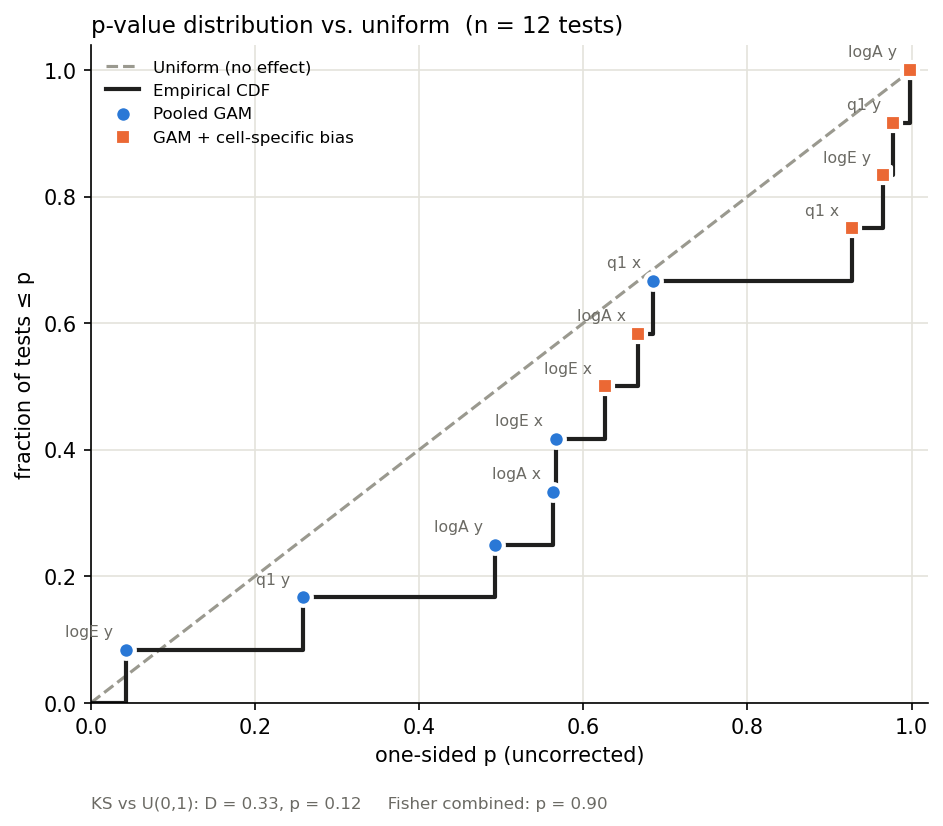

In [3]:
import pickle
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import combine_pvalues, kstest, ttest_1samp

channels = {
    "Ax": "logA x",
    "Ay": "logA y",
    "Ex": "logE x",
    "Ey": "logE y",
    "qx": "q1 x",
    "qy": "q1 y",
}

models = {
    "": ("Pooled GAM", "#2a78d6", "o"),
    "_ME": ("GAM + cell-specific bias", "#eb6834", "s"),
}

rows = []

for tag in channels:
    for suffix in models:
        filename = Path(f"../output/dataset_{tag}{suffix}.pkl")

        if not filename.exists():
            continue

        with open(filename, "rb") as f:
            delta = np.asarray(pickle.load(f), dtype=float)

        p_value = ttest_1samp(
            delta,
            popmean=0.0,
            alternative="greater",
        ).pvalue

        rows.append((p_value, tag, suffix))

rows.sort()

p = np.array([r[0] for r in rows])
n = len(p)

ks = kstest(p, "uniform")
fisher = combine_pvalues(p, method="fisher")

for i, (p_value, tag, suffix) in enumerate(rows, start=1):
    print(f"{i:2d}  p = {p_value:.3f}  {channels[tag]:7s} {models[suffix][0]:25s}  ECDF = {i / n:.2f}")

print()
print(f"KS vs U(0,1): D = {ks.statistic:.3f}, p = {ks.pvalue:.3f}")
print(f"Fisher combined: p = {fisher.pvalue:.3f}")

''' Plotting '''

fig, ax = plt.subplots(figsize=(6.4, 5.6), dpi=150)

ax.plot(
    [0, 1],
    [0, 1],
    color="#9a998f",
    linewidth=1.5,
    linestyle="--",
    zorder=1,
    label="Uniform (no effect)",
)

ax.step(
    np.r_[0, p, 1],
    np.r_[0, np.arange(1, n + 1) / n, 1],
    where="post",
    color="#1f1f1e",
    linewidth=2,
    zorder=2,
    label="Empirical CDF",
)

for i, (p_value, tag, suffix) in enumerate(rows, start=1):
    _, color, marker = models[suffix]

    ax.scatter(
        p_value,
        i / n,
        s=64,
        color=color,
        marker=marker,
        edgecolor="white",
        linewidth=2,
        zorder=3,
    )

    ax.annotate(
        channels[tag],
        (p_value, i / n),
        xytext=(-6, 5),
        textcoords="offset points",
        ha="right",
        va="bottom",
        fontsize=7.5,
        color="#6b6a64",
    )

for label, color, marker in models.values():
    ax.scatter([], [], s=64, color=color, marker=marker, edgecolor="white", linewidth=2, label=label)

ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.04)

ax.set_xlabel("one-sided p (uncorrected)")
ax.set_ylabel("fraction of tests ≤ p")
ax.set_title(f"p-value distribution vs. uniform  (n = {n} tests)", loc="left", fontsize=11)

ax.text(
    0.0,
    -0.16,
    f"KS vs U(0,1): D = {ks.statistic:.2f}, p = {ks.pvalue:.2f}     Fisher combined: p = {fisher.pvalue:.2f}",
    transform=ax.transAxes,
    fontsize=8,
    color="#6b6a64",
)

ax.grid(color="#e4e3dc", linewidth=0.8)
ax.set_axisbelow(True)

for side in ["top", "right"]:
    ax.spines[side].set_visible(False)

ax.legend(loc="upper left", frameon=False, fontsize=8)

fig.tight_layout()
plt.show()
